In [13]:
#import env
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]= os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]= os.getenv("TAVILY_API_KEY")   

### 1. State Backend

*maintain backend state and metadata*


Deep agent -> are internally -> lang graph agentic wokrflow ->  
all the files saved using state backend -> will only be saved inside : Lang graph state

-> what ever inof is saved-> will be available wirt the same thread**



In [14]:
# create deep agent

import os
from deepagents import create_deep_agent
from deepagents.backends import StateBackend

#---------------------
# 1. create the agent: both the agents below are same|| if we do not specify the state, by default files will be saved in lang graph state
#---------------------
agent = create_deep_agent(model="groq:openai/gpt-oss-20b")

agent2= create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=StateBackend() #save the files to lang graph state
)

#----------------------------------------------------------
# 2. Invoke the agent and ask it to WRITE a file
#    (StateBackend keeps that file inside LangGraph state
#----------------------------------------------------------
result = agent2.invoke({
    "messages":[{
        "role":"user",
        "content":(" Create a file at /notes/todo.txt with exact this content"
        "1. Record video "
        "2. Edit video "
        "3. Upload video "
        "Then tell me you have done it.")
    }]
})

# we will not see physically, but it will be saved to ram virtually, once agent is done, file will be deleted
print("\n-----------Agent reply--------------------------")
print(result['messages'][-1].content)


#wehen agents session is closed, the entire file will be deleted


-----------Agent reply--------------------------
✅ File `/notes/todo.txt` has been created with the requested content.


In [15]:
# check where these files are created and by which keys>>
result


{'messages': [HumanMessage(content=' Create a file at /notes/todo.txt with exact this content1. Record video 2. Edit video 3. Upload video Then tell me you have done it.', additional_kwargs={}, response_metadata={}, id='dbc30faa-8e13-4c24-9295-1a321ceffaed'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to create a file at /notes/todo.txt with content:\n\n1. Record video\n2. Edit video\n3. Upload video\n\nWe need to use write_file tool. Then respond that we have done it.', 'tool_calls': [{'id': 'fc_28a08f85-d8d2-425a-857c-a7d9fd21cbbf', 'function': {'arguments': '{"content":"1. Record video\\n2. Edit video\\n3. Upload video","file_path":"/notes/todo.txt"}', 'name': 'write_file'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 92, 'prompt_tokens': 1937, 'total_tokens': 2029, 'completion_time': 0.096682604, 'completion_tokens_details': {'reasoning_tokens': 47}, 'prompt_time': 0.111703612, 'prompt_tokens_details': None, 'queue_ti

In [16]:
#-----------------------------------------------------
# 3. CHECK the backend is working
#     with StateBackend, written files appear under result["files"]
#-------------------------------------------------------
print("\n -------Backend check--------------------------")
files = result.get("files", {})

if files:
    print(f"StateBackend is working - {len(files)} file(s) in state:")
    for path, content in files.items():
        print(f"\n {path}\n{'-'*40}\n{content}")
else:
    print("No files found in state. Either teh agent did not wite a file, or the backend is not wired up correctly")



 -------Backend check--------------------------
StateBackend is working - 1 file(s) in state:

 /notes/todo.txt
----------------------------------------
{'content': '1. Record video\n2. Edit video\n3. Upload video', 'encoding': 'utf-8', 'created_at': '2026-11-03T11:18:55.362381+00:00', 'modified_at': '2026-11-03T11:18:55.362381+00:00'}


In [17]:
# Read the file again from the same state:

#------------------------------------------------------------------
# 4. Prove persistane WITHIN the same thread:
#     feed the returned state back in and ask it to READ the file.
#------------------------------------------------------------------
followup = agent2.invoke({
    #carry forward prior messages + the file state
    "messages":result["messages"]+[{
        "role":"user",
        "content":"Read /notes/todo.txt back to me"
    }],
    "files":result.get("files",{}) #<-- pass virtual filesystem along
})

print("\n --------Read back (same-thread)-----------------------")
print(followup['messages'][-1].content)



 --------Read back (same-thread)-----------------------
Here’s the content of `/notes/todo.txt`:

```
1. Record video
2. Edit video
3. Upload video
```


### 2. File system backend:

File system backend(local disk): save the file in root dir (i.e hard disk)



In [18]:
# -----------------------------------------------------------------------------
# 1. Create the agent with a real-disk backend
#    root_dir="." -> files land relative to your current working directory
#    virtual_mode=True -> agent uses virtual paths like /notes/todo.txt,
#                         mapped onto root_dir
# -----------------------------------------------------------------------------
from deepagents.backends import FilesystemBackend

ROOT="."

aagent=create_deep_agent(model = "groq:openai/gpt-oss-20b",
                          backend=FilesystemBackend(root_dir=ROOT, virtual_mode=True))

print(f"✅ Agent created with FilesystemBackend(root_dir={ROOT!r}).")
print("   Files written by the agent will appear on your ACTUAL disk.")


✅ Agent created with FilesystemBackend(root_dir='.').
   Files written by the agent will appear on your ACTUAL disk.


In [19]:
# -----------------------------------------------------------------------------
# 2. Invoke the agent and ask it to WRITE a file
# -----------------------------------------------------------------------------

result = agent.invoke({
    "messages": [{
        "role": "user",
        "content": (
            "Create a file at /notes/todo.txt with exactly this content:\n"
            "1. Record video\n2. Edit video\n3. Upload video\n"
            "Then tell me you've done it."
        )
    }]
})

print("\n--- Agent reply -------------------------------------------------")
print(result["messages"][-1].content)


--- Agent reply -------------------------------------------------
✅ File `/notes/todo.txt` has been created with the requested content.


In [20]:
# -----------------------------------------------------------------------------
# 3. CHECK the backend is working — look on the REAL disk
#    With virtual_mode=True, /notes/todo.txt maps to ./notes/todo.txt
# -----------------------------------------------------------------------------
from pathlib import Path
print("\n--- Backend check (real filesystem) -----------------------------")
disk_path = Path(ROOT) / "notes" / "todo.txt"

if disk_path.exists():
    print(f"✅ FilesystemBackend is working — file exists on disk:")
    print(f"📄 {disk_path.resolve()}\n{'-' * 40}")
    print(disk_path.read_text())
else:
    print(f"⚠️  Expected file not found at {disk_path.resolve()}")
    print("    The agent may not have called the write tool, or the path "
          "mapping differs.")


--- Backend check (real filesystem) -----------------------------
⚠️  Expected file not found at D:\AgenticAI\deepagents-course\src\deepagents_course\notes\todo.txt
    The agent may not have called the write tool, or the path mapping differs.


In [22]:
# -----------------------------------------------------------------------------
# 4. Prove persistence ACROSS sessions:
#    Unlike StateBackend, this file survives even after Python exits.
#    A brand-new agent (fresh state) can read it back from disk.
# -----------------------------------------------------------------------------
fresh_agent = create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=FilesystemBackend(root_dir=ROOT, virtual_mode=True),
)

followup = fresh_agent.invoke({
    "messages": [{
        "role": "user",
        "content": "Read /notes/todo.txt back to me verbatim."
    }]
    # NOTE: no `files` state passed in — the file is read straight from disk
})

print("\n--- Read-back with a FRESH agent (proves disk persistence) ------")
print(followup["messages"][-1].content)


--- Read-back with a FRESH agent (proves disk persistence) ------
I couldn’t find the file you mentioned.  
The path `/notes/todo.txt` does not exist in the current file system. If you’d like to create it or check a different location, just let me know!


### Deep Agent - StoreBackend

Creates a deep agent backed by a LangGraph store, 

invokes it to write a file on one thread, 

then proves the backend works by reading that file back on a DIFFERENT thread — something StateBackend cannot do. """

In [23]:
from langgraph.store.memory import InMemoryStore
from deepagents.backends import StoreBackend
store = InMemoryStore()

agent = create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=StoreBackend(
        # Local dev: static namespace. No deployment runtime needed.
        # In a LangSmith Deployment you'd use the user-identity version.
        namespace=lambda rt: ("demo-user",),
    ),
    store=store,
)

print("✅ Agent created with StoreBackend + static namespace.")

✅ Agent created with StoreBackend + static namespace.


In [24]:
import os
import uuid
# -----------------------------------------------------------------------------
# 2. THREAD 1 — write a file
# -----------------------------------------------------------------------------
thread_1 = {"configurable": {"thread_id": str(uuid.uuid4())}}

result = agent.invoke(
    {
        "messages": [{
            "role": "user",
            "content": (
                "Create a file at /notes/todo.txt with exactly this content:\n"
                "1. Record video\n2. Edit video\n3. Upload video\n"
                "Then tell me you've done it."
            )
        }]
    },
    config=thread_1,
)

print("\n--- Agent reply (thread 1) --------------------------------------")
print(result["messages"][-1].content)


--- Agent reply (thread 1) --------------------------------------
✅ File `/notes/todo.txt` has been created with the requested content.


In [25]:
# --- Thread 2: read back on a DIFFERENT thread ---------------------------
thread_2 = {"configurable": {"thread_id": str(uuid.uuid4())}}
followup = agent.invoke(
    {"messages": [{
        "role": "user",
        "content": "Read /notes/todo.txt back to me verbatim."
    }]},
    config=thread_2,
)
print("\n--- Read-back on a different thread ---")
print(followup["messages"][-1].content)


--- Read-back on a different thread ---
1. Record video
2. Edit video
3. Upload video


In [26]:
#With StoreBackend + InMemoryStore, the file is not saved to disk at all. It lives in RAM, inside the InMemoryStore object, as an entry keyed under the namespace.



### Deep Agent Backends — Where Your Files Actually Live
Every Deep Agent works with a **virtual** filesystem: its tools read and write files using paths like /notes/todo.txt. But those paths are an abstraction. The backend decides where that data physically lives — and that single choice changes everything about persistence, sharing, and durability.

The agent code stays identical across all three. Only the backend changes.

**1. StateBackend (default)**
Files live **in the agent's LangGraph state** — i.e. in RAM, tied to a single thread. They're available during the run via result["files"], and you must manually carry that state forward to keep using them.

**Where**: in-memory dict, inside one thread's state
**Survives**: within a single conversation/thread only
G**one when**: the thread ends or the process exits
**Use it for**: ephemeral scratch space, temporary working files


2. **FilesystemBackend**
Files are written to your **real disk**, under root_dir. With virtual_mode=True, a virtual path like /notes/todo.txt maps to root_dir/notes/todo.txt. These are genuine files you can open in an editor or cat from a terminal.

**Where**: your actual filesystem, relative to root_dir
**Survives**: across process restarts — it's a real file
**Use it for**: when the agent should edit real project files
⚠️ **Caution**: grants the agent real read/write disk access — point it at a scratch directory, not anything important


3. **StoreBackend**
Files live in a **LangGraph store**, scoped by a namespace. This is the only backend whose files persist across threads/conversations — write on one thread, read back on another. With InMemoryStore this works within a single process; swap in a persistent store (e.g. Postgres-backed) for true cross-restart durability.

**Where**: inside the store object, under a namespace key
**Survives**: across threads sharing the same store
**Gone when**: the process exits (if using InMemoryStore) — use a persistent store to outlive restarts
**Use it for**: long-term memory, per-user file spaces



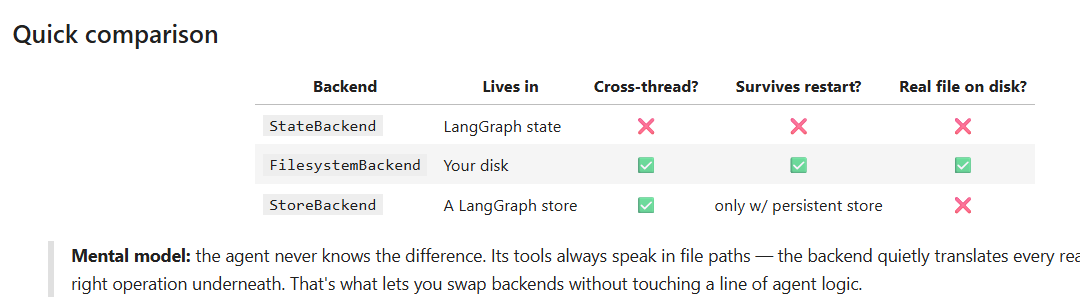


